# Notebook 02 - Data Preprocessing Pipeline

This notebook builds the complete preprocessing pipeline for SAR imagery:

1. Load raw SAR data
2. Handle NaN / invalid values
3. Speckle noise reduction (uniform filter)
4. Radiometric clipping & normalization
5. Image resizing to target size
6. Train/Val/Test split
7. Visualize before vs after preprocessing

## Step 1: Imports & Configuration

In [1]:
import os, sys
# Set project root path cleanly
ROOT_DIR = os.path.abspath('..') if os.path.exists('../config.json') else os.path.abspath('.')
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)

import numpy as np
import matplotlib.pyplot as plt
import rasterio
import torch
from scipy.ndimage import uniform_filter
from torch.utils.data import DataLoader
from dataset import Sen1FloodsDataset, get_train_val_test_splits
from utils import set_seed, load_config

config = load_config(os.path.join(ROOT_DIR, 'config.json'))
set_seed(config['training']['seed'])

plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor'] = '#161b22'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

S1_DIR = os.path.join(ROOT_DIR, config['data']['s1_dir'])
LABEL_DIR = os.path.join(ROOT_DIR, config['data']['label_dir'])
TARGET_SIZE = tuple(config['data']['target_size'])
print(f'Config loaded. Target size: {TARGET_SIZE}')


Config loaded. Target size: (256, 256)


## Step 2: Load Raw Data

In [2]:
s1_files = sorted([f for f in os.listdir(S1_DIR) if f.endswith('.tif')])
label_files = sorted([f for f in os.listdir(LABEL_DIR) if f.endswith('.tif')])
file_pairs = list(zip(
    [os.path.join(S1_DIR, f) for f in s1_files],
    [os.path.join(LABEL_DIR, f) for f in label_files]
))

print(f'Total image pairs: {len(file_pairs)}')
sample_s1_path, sample_label_path = file_pairs[0]
with rasterio.open(sample_s1_path) as src:
    raw_s1 = src.read().astype(np.float32)
with rasterio.open(sample_label_path) as src:
    raw_label = src.read(1).astype(np.float32)

print(f'Raw SAR shape: {raw_s1.shape}')
print(f'VV range: [{np.nanmin(raw_s1[0]):.2f}, {np.nanmax(raw_s1[0]):.2f}] dB')
print(f'VH range: [{np.nanmin(raw_s1[1]):.2f}, {np.nanmax(raw_s1[1]):.2f}] dB')
print(f'NaN count: {int(np.isnan(raw_s1).sum())}')


Total image pairs: 40
Raw SAR shape: (2, 512, 512)
VV range: [-39.31, 8.59] dB
VH range: [-47.38, -1.38] dB
NaN count: 0


## Step 3: Speckle Noise Reduction

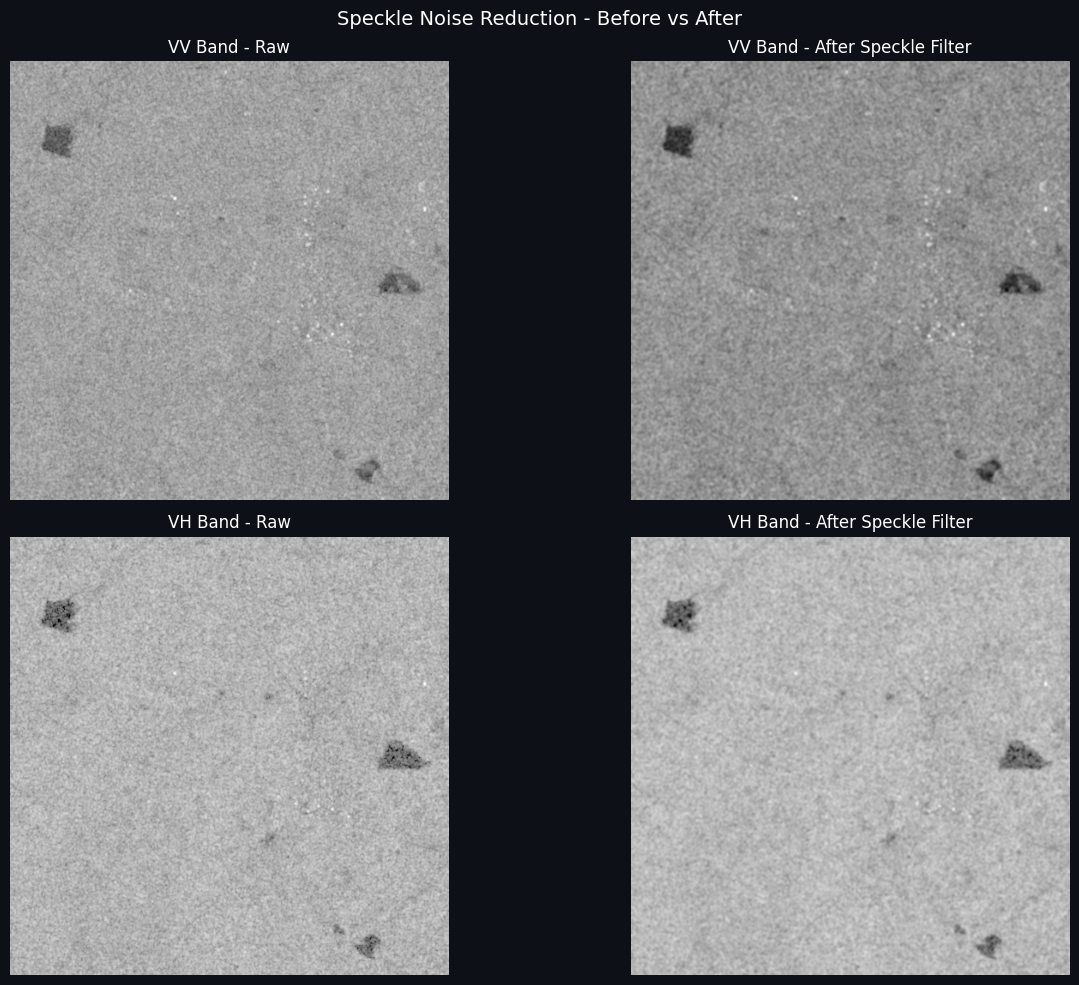

In [3]:
def apply_speckle_filter(image, size=3):
    filtered = np.zeros_like(image)
    for band in range(image.shape[0]):
        filtered[band] = uniform_filter(image[band], size=size)
    return filtered

raw_nan_filled = np.stack([
    np.nan_to_num(raw_s1[0], nan=-25.0),
    np.nan_to_num(raw_s1[1], nan=-30.0)
])

filtered_s1 = apply_speckle_filter(raw_nan_filled, size=3)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Speckle Noise Reduction - Before vs After', fontsize=14, color='white')

axes[0][0].imshow(raw_nan_filled[0], cmap='gray')
axes[0][0].set_title('VV Band - Raw')
axes[0][0].axis('off')

axes[0][1].imshow(filtered_s1[0], cmap='gray')
axes[0][1].set_title('VV Band - After Speckle Filter')
axes[0][1].axis('off')

axes[1][0].imshow(raw_nan_filled[1], cmap='gray')
axes[1][0].set_title('VH Band - Raw')
axes[1][0].axis('off')

axes[1][1].imshow(filtered_s1[1], cmap='gray')
axes[1][1].set_title('VH Band - After Speckle Filter')
axes[1][1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/preprocess_speckle.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## Step 4: Radiometric Clipping & Normalization

After normalization:
  VV range: [0.036, 1.000]
  VH range: [0.000, 1.000]


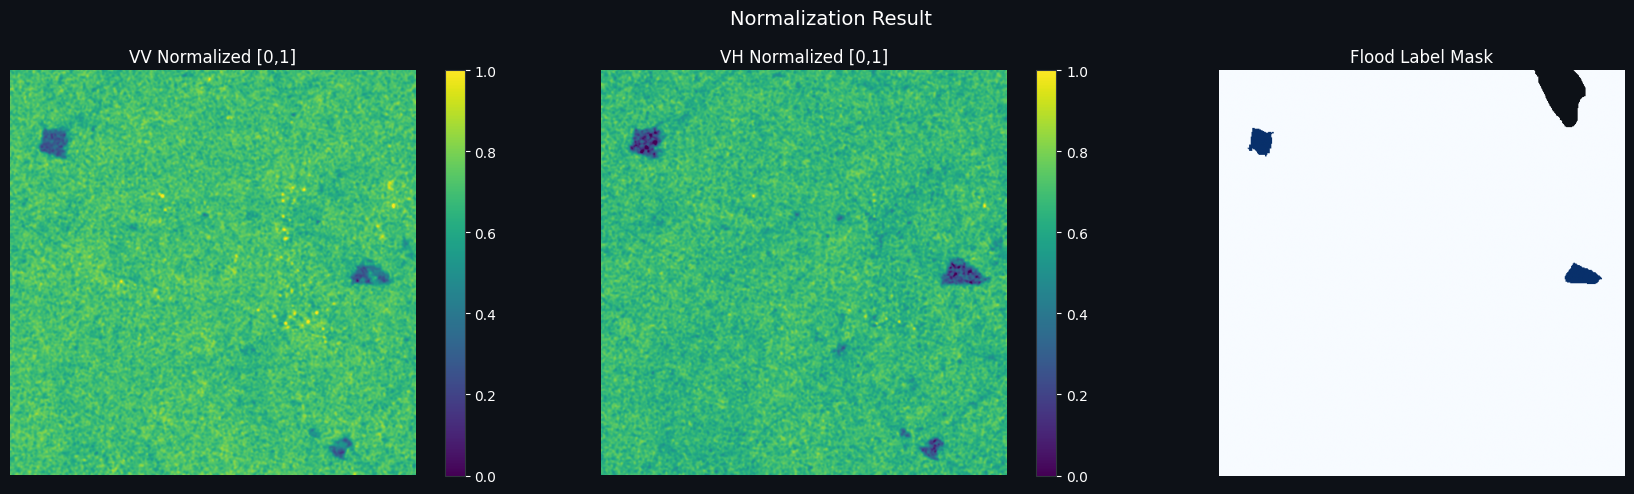

In [4]:
def normalize_s1(filtered):
    vv = np.clip(filtered[0], -30.0, 0.0)
    vh = np.clip(filtered[1], -35.0, -5.0)
    vv_norm = (vv - (-30.0)) / 30.0
    vh_norm = (vh - (-35.0)) / 30.0
    return np.stack([vv_norm, vh_norm], axis=0)

normalized_s1 = normalize_s1(filtered_s1)

print(f'After normalization:')
print(f'  VV range: [{normalized_s1[0].min():.3f}, {normalized_s1[0].max():.3f}]')
print(f'  VH range: [{normalized_s1[1].min():.3f}, {normalized_s1[1].max():.3f}]')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Normalization Result', fontsize=14, color='white')

axes[0].imshow(normalized_s1[0], cmap='viridis', vmin=0, vmax=1)
axes[0].set_title('VV Normalized [0,1]')
axes[0].axis('off')
plt.colorbar(axes[0].images[0], ax=axes[0])

axes[1].imshow(normalized_s1[1], cmap='viridis', vmin=0, vmax=1)
axes[1].set_title('VH Normalized [0,1]')
axes[1].axis('off')
plt.colorbar(axes[1].images[0], ax=axes[1])

flood_label = np.where(raw_label == -1, np.nan, raw_label)
axes[2].imshow(flood_label, cmap='Blues', vmin=0, vmax=1)
axes[2].set_title('Flood Label Mask')
axes[2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/preprocess_normalized.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## Step 5: Train / Validation / Test Split

In [5]:
train_idx, val_idx, test_idx = get_train_val_test_splits(
    len(file_pairs), config['data']['split_ratio']
)

train_pairs = [file_pairs[i] for i in train_idx]
val_pairs   = [file_pairs[i] for i in val_idx]
test_pairs  = [file_pairs[i] for i in test_idx]

print(f'Dataset splits (70/15/15):')
print(f'  Train: {len(train_pairs)} samples')
print(f'  Val:   {len(val_pairs)} samples')
print(f'  Test:  {len(test_pairs)} samples')

train_dataset = Sen1FloodsDataset(train_pairs, target_size=TARGET_SIZE)
val_dataset   = Sen1FloodsDataset(val_pairs, target_size=TARGET_SIZE)
test_dataset  = Sen1FloodsDataset(test_pairs, target_size=TARGET_SIZE)

train_loader = DataLoader(train_dataset, batch_size=config['training']['batch_size'],
                          shuffle=True, num_workers=config['data']['num_workers'])
val_loader   = DataLoader(val_dataset, batch_size=config['training']['batch_size'],
                          shuffle=False, num_workers=config['data']['num_workers'])
test_loader  = DataLoader(test_dataset, batch_size=1, shuffle=False)

print('DataLoaders ready!')


Dataset splits (70/15/15):
  Train: 28 samples
  Val:   6 samples
  Test:  6 samples
DataLoaders ready!


## Step 6: Visualize Preprocessed Samples

Batch shape: torch.Size([16, 2, 256, 256])  (B x C x H x W)
Label shape: torch.Size([16, 256, 256])


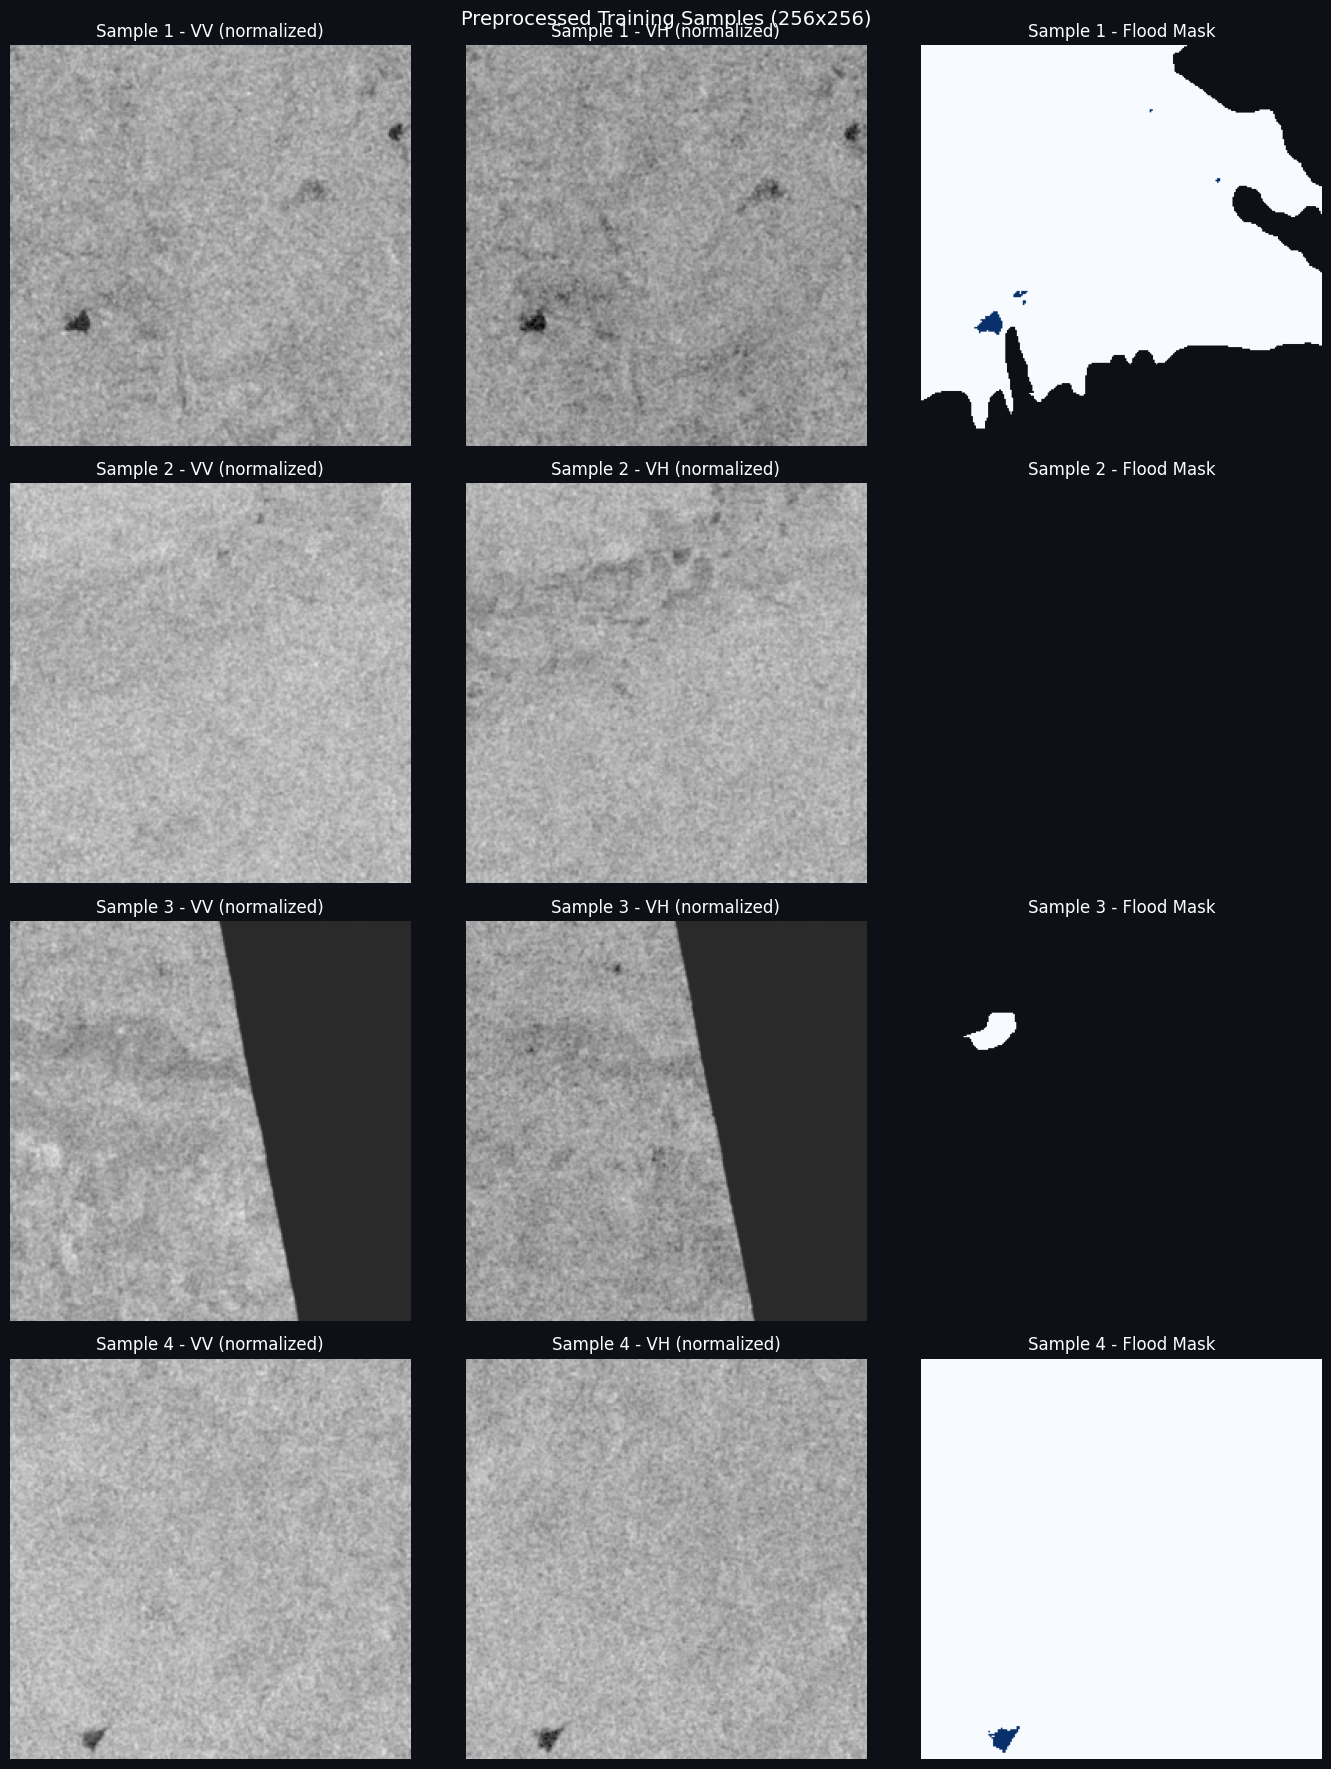

In [6]:
batch_imgs, batch_labels = next(iter(train_loader))
print(f'Batch shape: {batch_imgs.shape}  (B x C x H x W)')
print(f'Label shape: {batch_labels.shape}')

fig, axes = plt.subplots(4, 3, figsize=(14, 18))
fig.suptitle('Preprocessed Training Samples (256x256)', fontsize=14, color='white')

for i in range(min(4, batch_imgs.shape[0])):
    vv = batch_imgs[i, 0].numpy()
    vh = batch_imgs[i, 1].numpy()
    lbl = batch_labels[i].numpy().astype(float)
    lbl[lbl == -1] = np.nan

    axes[i][0].imshow(vv, cmap='gray', vmin=0, vmax=1)
    axes[i][0].set_title(f'Sample {i+1} - VV (normalized)')
    axes[i][0].axis('off')

    axes[i][1].imshow(vh, cmap='gray', vmin=0, vmax=1)
    axes[i][1].set_title(f'Sample {i+1} - VH (normalized)')
    axes[i][1].axis('off')

    axes[i][2].imshow(lbl, cmap='Blues', vmin=0, vmax=1)
    axes[i][2].set_title(f'Sample {i+1} - Flood Mask')
    axes[i][2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/preprocess_samples.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
